# 01 – Sélection du document, extraction et découpage
**Travail demandé 1 et 2** : analyser un PDF technique de maintenance (variateur ABB ACS580) et en extraire le **texte**, les **tableaux** et les **images**.

- PyMuPDF : texte par blocs + images
- pdfplumber : tableaux → Markdown
- **LlamaIndex** `SentenceSplitter` : découpage du texte en passages (chunks)

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from src import config
PDF = config.PDF_DIR / "ABB_ACS580_Guide_Variateur.pdf"
print("Projet :", ROOT, "| PDF existe :", PDF.exists())

Projet : c:\Users\OMEN\Downloads\parti 1 projet agent | PDF existe : True


In [2]:
from src.ingestion import parse_pdf, save_elements, slugify
elements = parse_pdf(PDF)
doc_id = slugify(PDF.name)
from collections import Counter
print(len(elements), 'éléments :', Counter(e.type for e in elements))

60 éléments : Counter({'table': 28, 'text': 24, 'image': 8})


## Répartition par page

In [3]:
import pandas as pd
df = pd.DataFrame([{'page': e.page, 'type': e.type, 'longueur': len(e.content)} for e in elements])
df.pivot_table(index='page', columns='type', values='longueur', aggfunc='count', fill_value=0)

type,image,table,text
page,,,
1,1,1,1
2,0,0,1
3,0,1,2
4,1,0,2
5,1,1,1
6,1,3,1
7,1,3,1
8,0,3,1
9,1,2,1


## Exemple de passage de texte (chunk LlamaIndex)

In [4]:
txt = [e for e in elements if e.type == 'text']
print(txt[3].id, '| page', txt[3].page)
print(txt[3].content)

abb_acs580_guide_variateur-p3-text1 | page 3
•
Protection du moteur et de la machine : surintensité, surcharge thermique, perte de
phase, défaut de terre, calage (stall), survitesse.
•
Intégration à l'automatisme : commande par entrées/sorties, bus de terrain (Modbus
RTU, PROFINET, EtherNet/IP…), régulateur PID intégré.
2. Principe de fonctionnement
Un variateur de fréquence comme l'ACS580 est composé de trois étages de puissance (voir
Figure 1) :


## Exemple de tableau extrait (Markdown)

In [5]:
from IPython.display import Markdown, display
tables = [e for e in elements if e.type == 'table']
codes = [t for t in tables if '2310' in t.content]
print(len(tables), 'morceaux de tableaux')
display(Markdown(codes[0].content if codes else tables[0].content))

28 morceaux de tableaux


Tableau extrait de la page 12

| Code | Nom (panneau) | Cause probable | Action corrective |
|---|---|---|---|
| 2281 | Calibration – Étalonnage | Écart de mesure du courant de sortie trop important lors de l'étalonnage. | Relancer l'étalonnage de la mesure de courant ; si le défaut persiste, contacter ABB. |
| 2310 | Overcurrent – Surintensité | Courant de sortie supérieur à la limite interne : rampe d'accélération trop courte, charge bloquée, court-circuit ou défaut d'isolement moteur/câble, données moteur erronées, IGBT défectueux. | Augmenter 23.12/23.13, vérifier la charge mécanique, mesurer l'isolement du moteur et du câble, vérifier le groupe 99 et refaire l'ID run. Voir Figure 7. |
| 2330 | Earth leakage – Fuite à la terre | Déséquilibre de charge typiquement dû à un défaut de terre dans le moteur ou le câble moteur (humidité, isolant dégradé). | Vérifier l'absence de condensateurs de compensation ou parafoudres sur le câble moteur ; mesurer l'isolement moteur et câble ; si aucun défaut, contacter ABB. Programmable : 31.20. |
| 2340 | Short circuit – Court-circuit | Court-circuit dans le moteur ou le câble moteur. | Vérifier le moteur et le câble ; s'assurer qu'aucun condensateur n'est raccordé côté moteur. |
| 3130 | Input phase loss – Perte de phase réseau | La tension du bus DC oscille à cause d'une phase réseau manquante ou d'un fusible fondu. | Vérifier les fusibles d'alimentation, les connexions réseau et le déséquilibre des tensions. Programmable : 31.21. |
| 3181 | Wiring or earth fault – Erreur de câblage | Câble réseau et câble moteur inversés (moteur raccordé sur les bornes d'entrée) ou défaut de terre. | Vérifier les raccordements puissance ; fréquent après une nouvelle installation. Programmable : 31.23. |

## Images extraites

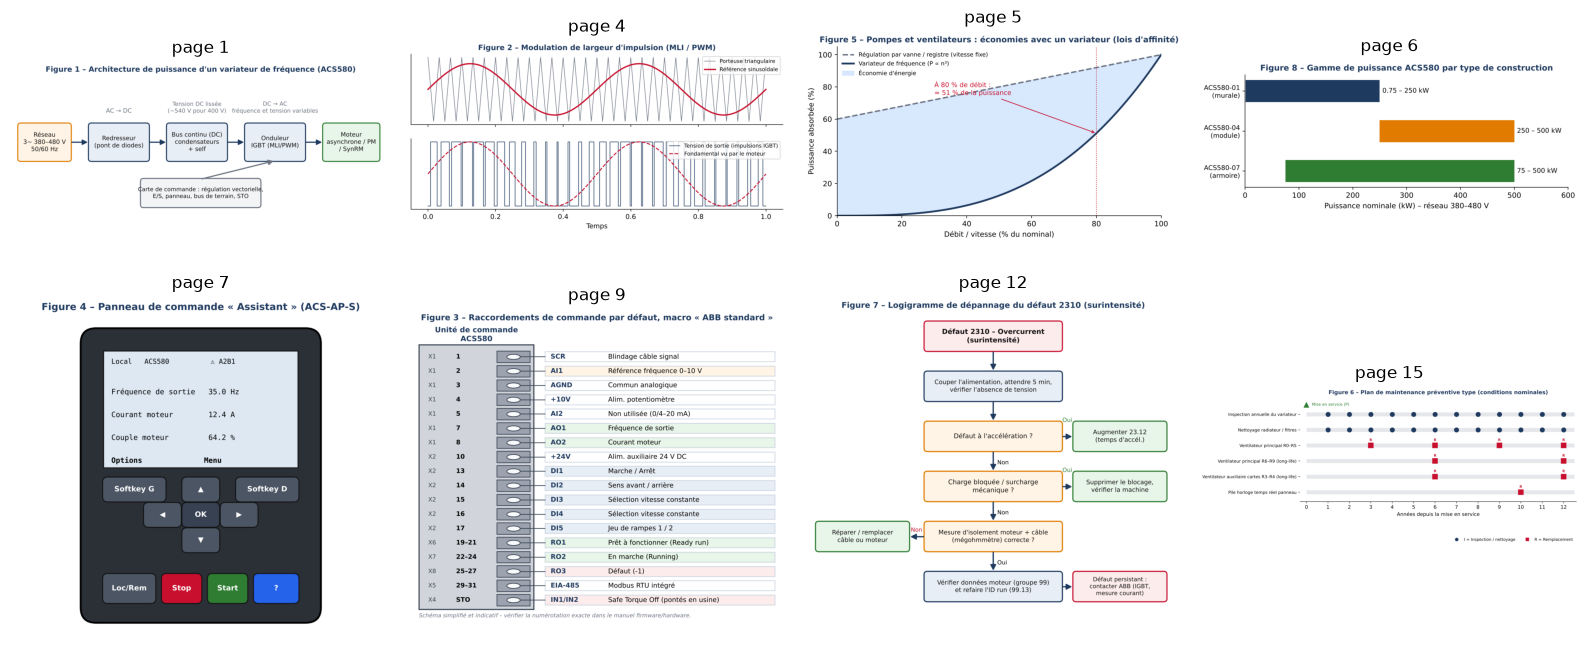

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
imgs = [e for e in elements if e.type == 'image']
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, e in zip(axs.flat, imgs):
    ax.imshow(Image.open(config.abs_path(e.image_path))); ax.set_title(f'page {e.page}'); ax.axis('off')
plt.tight_layout(); plt.show()

In [7]:
path = save_elements(elements, doc_id)
print('Sauvegardé :', path)

Sauvegardé : C:\Users\OMEN\Downloads\parti 1 projet agent\data\elements\abb_acs580_guide_variateur.json
